In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn
%matplotlib inline

from sklearn.datasets import load_diabetes
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, cross_val_score, KFold, train_test_split
from sklearn.metrics import r2_score

# Load the dataset

In [5]:
dataset = load_diabetes()
X = dataset.data
y = dataset.target

print("X shape: {}".format(X.shape))
print("y shape: {}".format(y.shape))

X shape: (442, 10)
y shape: (442,)


# Define model and hyperparameters to optimize

In [6]:
lr = Lasso(random_state=0) # model class
alphas = np.logspace(-5, 0, 11)
params = {'alpha': alphas}

In [7]:
alphas

array([1.00000000e-05, 3.16227766e-05, 1.00000000e-04, 3.16227766e-04,
       1.00000000e-03, 3.16227766e-03, 1.00000000e-02, 3.16227766e-02,
       1.00000000e-01, 3.16227766e-01, 1.00000000e+00])

# Non-nested cross validation

In [11]:
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.3)
gridcv = GridSearchCV(estimator=lr, param_grid=params, cv=5)
gridcv.fit(X_trainval, y_trainval)

GridSearchCV(cv=5, estimator=Lasso(random_state=0),
             param_grid={'alpha': array([1.00000000e-05, 3.16227766e-05, 1.00000000e-04, 3.16227766e-04,
       1.00000000e-03, 3.16227766e-03, 1.00000000e-02, 3.16227766e-02,
       1.00000000e-01, 3.16227766e-01, 1.00000000e+00])})

In [9]:
# best hyperparameter combination
gridcv.best_params_

{'alpha': 1e-05}

In [16]:
# accuracy values for each hyperparameter combination
scores = gridcv.cv_results_['mean_test_score']

In [13]:
# standard deviation of accuracy values for each hyperparameter combination
score_sds = gridcv.cv_results_['std_test_score']

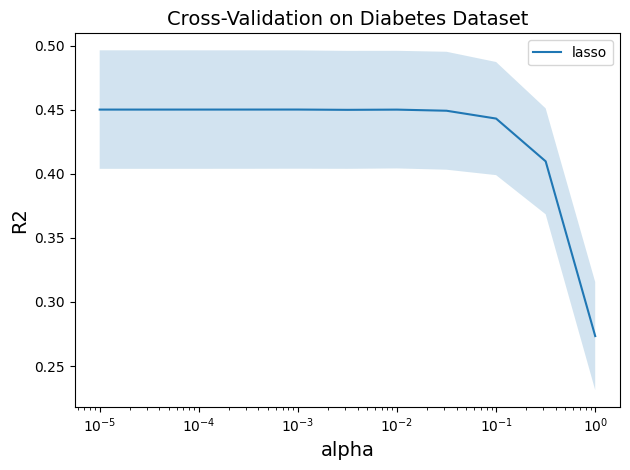

In [17]:
# lasso model R2s
plt.semilogx(alphas, scores)
plt.fill_between(alphas, scores-score_sds, 
                 scores+score_sds, alpha=0.2)

# plot title, axis labels, etc.
fs = 14
plt.title('Cross-Validation on Diabetes Dataset', fontsize=fs)
plt.xlabel('alpha', fontsize=fs)
plt.ylabel('R2', fontsize=fs)
plt.legend(['lasso'])
plt.tight_layout()
plt.show()

In [18]:
y_pred = gridcv.best_estimator_.predict(X_test)
print("Test R2: {:0.4f}".format(r2_score(y_test, y_pred)))

Test R2: 0.5233


# Nested cross validation

In [19]:
# define inner and outer CV objects
inner_cv = KFold(n_splits=5, shuffle=True, random_state=0)
outer_cv = KFold(n_splits=5, shuffle=True, random_state=0)

In [20]:
# the cross_val_score function takes in GridSearchCV as an estimator and outputs test set accuracies
gridcv = GridSearchCV(estimator=lr, param_grid=params, cv=inner_cv)
nested_score = cross_val_score(estimator=gridcv, X=X, y=y, cv=outer_cv)

In [21]:
# mean R2 across 5 outer folds
print("Mean R2: {:0.4f}".format(nested_score.mean()))
print("Stdv R2: {:0.4f}".format(nested_score.std()))

Mean R2: 0.4872
Stdv R2: 0.0911


### Is the model fitting stable?

In [22]:
for trainval_index, test_index in outer_cv.split(X):
    X_trainval, X_test = X[trainval_index], X[test_index]
    y_trainval, y_test = y[trainval_index], y[test_index]
    
    gridcv.fit(X_trainval, y_trainval)
    print("Best hyperparameters: ", gridcv.best_params_)

Best hyperparameters:  {'alpha': np.float64(1e-05)}
Best hyperparameters:  {'alpha': np.float64(0.03162277660168379)}
Best hyperparameters:  {'alpha': np.float64(0.1)}
Best hyperparameters:  {'alpha': np.float64(0.01)}
Best hyperparameters:  {'alpha': np.float64(0.03162277660168379)}
